In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


from matplotlib import rc
rc('font',**{'family':'serif','serif':['Times New Roman']})
rc('text', usetex=True)

In [2]:
df = pd.read_csv('centros_Yobod.txt', delim_whitespace = True, header=None )    

C:\Users\PC\AppData\Local\Temp\ipykernel_20620\1322970665.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('centros_Yobod.txt', delim_whitespace = True, header=None )


In [3]:
df.head(10)

,0,1,2
0,1.0,58.632652,238.720154
1,2.0,80.307921,158.694751
2,3.0,79.302149,178.699052
3,4.0,79.563112,199.982923
4,5.0,79.548695,216.988388
5,6.0,78.464222,237.769042
6,7.0,79.218096,257.705796
7,8.0,79.329450,279.007731
8,9.0,81.385479,299.579844
9,10.0,80.474125,320.358956


In [4]:
df.rename(columns={0:'pos', 2:'y', 1:'x'}, inplace=True)

In [5]:
df.head(10)

,pos,x,y
0,1.0,58.632652,238.720154
1,2.0,80.307921,158.694751
2,3.0,79.302149,178.699052
3,4.0,79.563112,199.982923
4,5.0,79.548695,216.988388
5,6.0,78.464222,237.769042
6,7.0,79.218096,257.705796
7,8.0,79.329450,279.007731
8,9.0,81.385479,299.579844
9,10.0,80.474125,320.358956


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253 entries, 0 to 252
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pos     253 non-null    float64
 1   x       253 non-null    float64
 2   y       253 non-null    float64
dtypes: float64(3)
memory usage: 6.1 KB


In [7]:
df.describe()

,pos,x,y
count,253.000000,253.000000,253.000000
mean,127.000000,240.944210,237.856693
std,73.179004,90.872520,91.108741
min,1.000000,58.632652,52.682295
25%,64.000000,160.495796,158.851333
50%,127.000000,240.411635,238.239457
75%,190.000000,320.633415,317.675158
max,253.000000,425.114460,420.625161


In [8]:
matA = np.zeros((480,480))

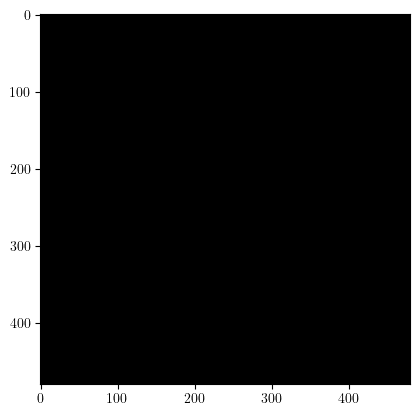

In [9]:
plt.imshow(matA, cmap="gray")

In [10]:
delta = 0.02 #There were 0.4 mm every 20 pixels. So, scaling, gives 0.02 mm per pixel
X = np.linspace(0, 480*delta + delta, 480)

In [11]:
np.max(X)

9.62

In [12]:
#The coordinates are in pixels, so they are integers and should be threated as that
#However, to be more exact, it will be better leave the x and y coordinates with decimals and then apply the 
#scale paratemer. So, this is only for give and idea, it is not correct to perform computations
df_img_pattern = np.floor(df).astype(int)

In [13]:
df_img_pattern.head(5)

,pos,x,y
0,1,58,238
1,2,80,158
2,3,79,178
3,4,79,199
4,5,79,216


In [14]:
df.head(5)

,pos,x,y
0,1.0,58.632652,238.720154
1,2.0,80.307921,158.694751
2,3.0,79.302149,178.699052
3,4.0,79.563112,199.982923
4,5.0,79.548695,216.988388


In [15]:
N = df.shape[0] #Number of centroids in the pattern
matA = np.zeros((480,480))

counter = 0 #Just to verify
for ii in range(0,N):
    matA[df_img_pattern["x"][ii]][df_img_pattern["y"][ii]] = 1
    counter += 1
counter    

253

Text(0, 0.5, 'Height [pixels]')

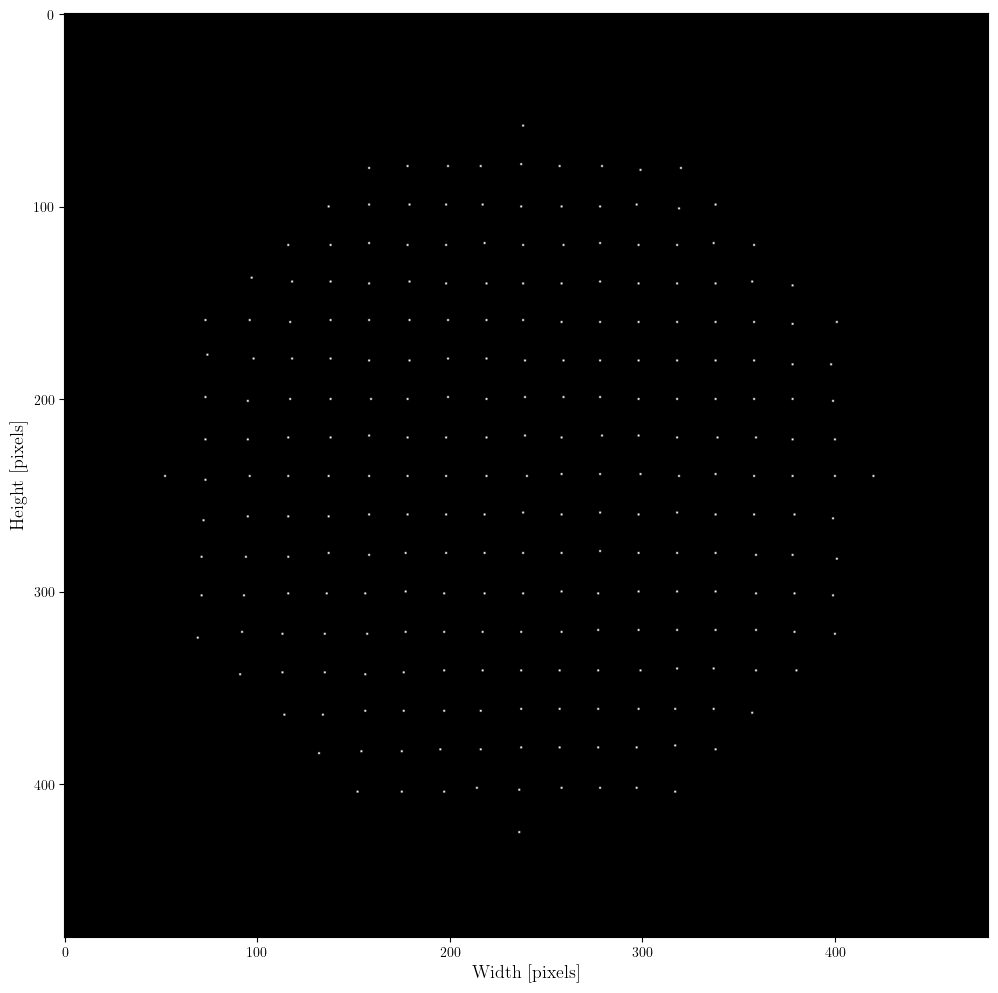

In [16]:
plt.figure(figsize=(12,12))
plt.imshow(matA, cmap="gray")
plt.xlabel('Width [pixels]', size=13)
plt.ylabel('Height [pixels]', size=13)

In [17]:
df["x_d"] = df["x"] * delta
df["y_d"] = df["y"] * delta

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253 entries, 0 to 252
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pos     253 non-null    float64
 1   x       253 non-null    float64
 2   y       253 non-null    float64
 3   x_d     253 non-null    float64
 4   y_d     253 non-null    float64
dtypes: float64(5)
memory usage: 10.0 KB


In [19]:
df.head(10)

,pos,x,y,x_d,y_d
0,1.0,58.632652,238.720154,1.172653,4.774403
1,2.0,80.307921,158.694751,1.606158,3.173895
2,3.0,79.302149,178.699052,1.586043,3.573981
3,4.0,79.563112,199.982923,1.591262,3.999658
4,5.0,79.548695,216.988388,1.590974,4.339768
5,6.0,78.464222,237.769042,1.569284,4.755381
6,7.0,79.218096,257.705796,1.584362,5.154116
7,8.0,79.329450,279.007731,1.586589,5.580155
8,9.0,81.385479,299.579844,1.627710,5.991597
9,10.0,80.474125,320.358956,1.609483,6.407179


In [20]:
mat_R_X = np.zeros((19,19))

In [21]:
mat_R_X[0][9] = df["x_d"][0]

mat_R_X[1][5] = df["x_d"][1]
mat_R_X[1][6] = df["x_d"][2]
mat_R_X[1][7] = df["x_d"][3]
mat_R_X[1][8] = df["x_d"][4]
mat_R_X[1][9] = df["x_d"][5]
mat_R_X[1][10] = df["x_d"][6]
mat_R_X[1][11] = df["x_d"][7]
mat_R_X[1][12] = df["x_d"][8]
mat_R_X[1][13] = df["x_d"][9]

mat_R_X[2][4] = df["x_d"][10]
mat_R_X[2][5] = df["x_d"][11]
mat_R_X[2][6] = df["x_d"][12]
mat_R_X[2][7] = df["x_d"][13]
mat_R_X[2][8] = df["x_d"][14]
mat_R_X[2][9] = df["x_d"][15]
mat_R_X[2][10] = df["x_d"][16]
mat_R_X[2][11] = df["x_d"][17]
mat_R_X[2][12] = df["x_d"][18]
mat_R_X[2][13] = df["x_d"][19]
mat_R_X[2][14] = df["x_d"][20]

mat_R_X[3][3] = df["x_d"][21]
mat_R_X[3][4] = df["x_d"][22]
mat_R_X[3][5] = df["x_d"][23]
mat_R_X[3][6] = df["x_d"][24]
mat_R_X[3][7] = df["x_d"][25]
mat_R_X[3][8] = df["x_d"][26]
mat_R_X[3][9] = df["x_d"][27]
mat_R_X[3][10] = df["x_d"][28]
mat_R_X[3][11] = df["x_d"][29]
mat_R_X[3][12] = df["x_d"][30]
mat_R_X[3][13] = df["x_d"][31]
mat_R_X[3][14] = df["x_d"][32]
mat_R_X[3][15] = df["x_d"][33]

mat_R_X[4][2] = df["x_d"][34]
mat_R_X[4][3] = df["x_d"][35]
mat_R_X[4][4] = df["x_d"][36]
mat_R_X[4][5] = df["x_d"][37]
mat_R_X[4][6] = df["x_d"][38]
mat_R_X[4][7] = df["x_d"][39]
mat_R_X[4][8] = df["x_d"][40]
mat_R_X[4][9] = df["x_d"][41]
mat_R_X[4][10] = df["x_d"][42]
mat_R_X[4][11] = df["x_d"][43]
mat_R_X[4][12] = df["x_d"][44]
mat_R_X[4][13] = df["x_d"][45]
mat_R_X[4][14] = df["x_d"][46]
mat_R_X[4][15] = df["x_d"][47]
mat_R_X[4][16] = df["x_d"][48]


In [22]:
counter = 49
for ii in range(5,14):
    if (ii == 9 ):
        for jj in range(0, 19):
            mat_R_X[ii][jj] = df["x_d"][counter]     
            counter+=1        
    else:
        for jj in range(1,18):
            mat_R_X[ii][jj] = df["x_d"][counter] 
            counter+=1

In [23]:
mat_R_X[14][2] = df["x_d"][204]
mat_R_X[14][3] = df["x_d"][205]
mat_R_X[14][4] = df["x_d"][206]
mat_R_X[14][5] = df["x_d"][207]
mat_R_X[14][6] = df["x_d"][208]
mat_R_X[14][7] = df["x_d"][209]
mat_R_X[14][8] = df["x_d"][210]
mat_R_X[14][9] = df["x_d"][211]
mat_R_X[14][10] = df["x_d"][212]
mat_R_X[14][11] = df["x_d"][213]
mat_R_X[14][12] = df["x_d"][214]
mat_R_X[14][13] = df["x_d"][215]
mat_R_X[14][14] = df["x_d"][216]
mat_R_X[14][15] = df["x_d"][217]
mat_R_X[14][16] = df["x_d"][218]

In [24]:
mat_R_X[15][3] = df["x_d"][219]
mat_R_X[15][4] = df["x_d"][220]
mat_R_X[15][5] = df["x_d"][221]
mat_R_X[15][6] = df["x_d"][222]
mat_R_X[15][7] = df["x_d"][223]
mat_R_X[15][8] = df["x_d"][224]
mat_R_X[15][9] = df["x_d"][225]
mat_R_X[15][10] = df["x_d"][226]
mat_R_X[15][11] = df["x_d"][227]
mat_R_X[15][12] = df["x_d"][228]
mat_R_X[15][13] = df["x_d"][229]
mat_R_X[15][14] = df["x_d"][230]
mat_R_X[15][15] = df["x_d"][231]

In [25]:
mat_R_X[16][4] = df["x_d"][232]
mat_R_X[16][5] = df["x_d"][233]
mat_R_X[16][6] = df["x_d"][234]
mat_R_X[16][7] = df["x_d"][235]
mat_R_X[16][8] = df["x_d"][236]
mat_R_X[16][9] = df["x_d"][237]
mat_R_X[16][10] = df["x_d"][238]
mat_R_X[16][11] = df["x_d"][239]
mat_R_X[16][12] = df["x_d"][240]
mat_R_X[16][13] = df["x_d"][241]
mat_R_X[16][14] = df["x_d"][242]

In [26]:
mat_R_X[17][5] = df["x_d"][243]
mat_R_X[17][6] = df["x_d"][244]
mat_R_X[17][7] = df["x_d"][245]
mat_R_X[17][8] = df["x_d"][246]
mat_R_X[17][9] = df["x_d"][247]
mat_R_X[17][10] = df["x_d"][248]
mat_R_X[17][11] = df["x_d"][249]
mat_R_X[17][12] = df["x_d"][250]
mat_R_X[17][13] = df["x_d"][251]

In [27]:
mat_R_X[18][9] = df["x_d"][252]

Text(0.5, 1.0, 'X positions')

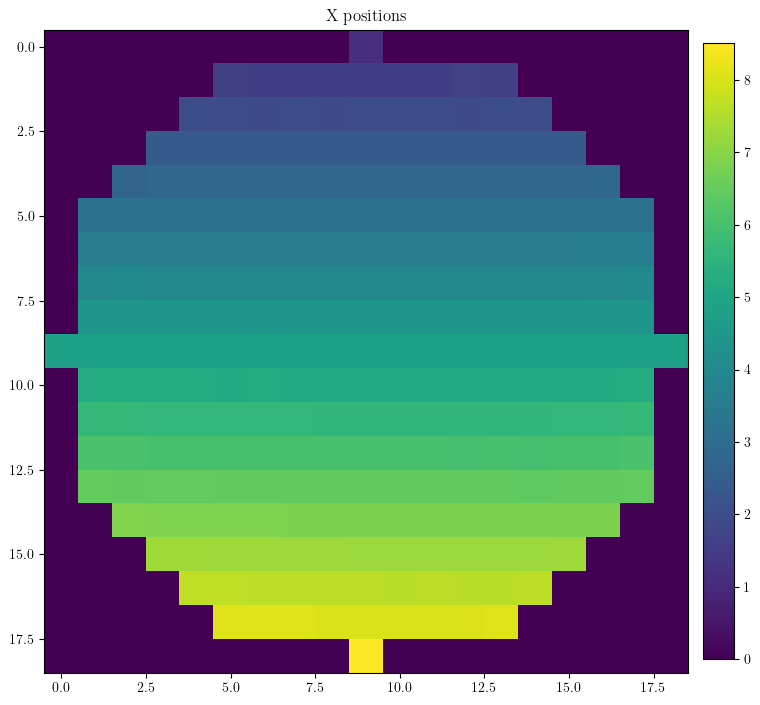

In [28]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_R_X) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("X positions")

In [29]:
npmat_R_X = np.array(mat_R_X)

In [30]:
np.max(npmat_R_X)

8.5022892

Now, we are going to stablish the Y positions, in order to compute the quantities in which we are interested in.

In [31]:
mat_R_Y = np.zeros((19,19))

In [32]:
mat_R_Y[0][9] = df["y_d"][0]

mat_R_Y[1][5] = df["y_d"][1]
mat_R_Y[1][6] = df["y_d"][2]
mat_R_Y[1][7] = df["y_d"][3]
mat_R_Y[1][8] = df["y_d"][4]
mat_R_Y[1][9] = df["y_d"][5]
mat_R_Y[1][10] = df["y_d"][6]
mat_R_Y[1][11] = df["y_d"][7]
mat_R_Y[1][12] = df["y_d"][8]
mat_R_Y[1][13] = df["y_d"][9]

mat_R_Y[2][4] = df["y_d"][10]
mat_R_Y[2][5] = df["y_d"][11]
mat_R_Y[2][6] = df["y_d"][12]
mat_R_Y[2][7] = df["y_d"][13]
mat_R_Y[2][8] = df["y_d"][14]
mat_R_Y[2][9] = df["y_d"][15]
mat_R_Y[2][10] = df["y_d"][16]
mat_R_Y[2][11] = df["y_d"][17]
mat_R_Y[2][12] = df["y_d"][18]
mat_R_Y[2][13] = df["y_d"][19]
mat_R_Y[2][14] = df["y_d"][20]

mat_R_Y[3][3] = df["y_d"][21]
mat_R_Y[3][4] = df["y_d"][22]
mat_R_Y[3][5] = df["y_d"][23]
mat_R_Y[3][6] = df["y_d"][24]
mat_R_Y[3][7] = df["y_d"][25]
mat_R_Y[3][8] = df["y_d"][26]
mat_R_Y[3][9] = df["y_d"][27]
mat_R_Y[3][10] = df["y_d"][28]
mat_R_Y[3][11] = df["y_d"][29]
mat_R_Y[3][12] = df["y_d"][30]
mat_R_Y[3][13] = df["y_d"][31]
mat_R_Y[3][14] = df["y_d"][32]
mat_R_Y[3][15] = df["y_d"][33]

mat_R_Y[4][2] = df["y_d"][34]
mat_R_Y[4][3] = df["y_d"][35]
mat_R_Y[4][4] = df["y_d"][36]
mat_R_Y[4][5] = df["y_d"][37]
mat_R_Y[4][6] = df["y_d"][38]
mat_R_Y[4][7] = df["y_d"][39]
mat_R_Y[4][8] = df["y_d"][40]
mat_R_Y[4][9] = df["y_d"][41]
mat_R_Y[4][10] = df["y_d"][42]
mat_R_Y[4][11] = df["y_d"][43]
mat_R_Y[4][12] = df["y_d"][44]
mat_R_Y[4][13] = df["y_d"][45]
mat_R_Y[4][14] = df["y_d"][46]
mat_R_Y[4][15] = df["y_d"][47]
mat_R_Y[4][16] = df["y_d"][48]


In [33]:
counter = 49
for ii in range(5,14):
    if (ii == 9 ):
        for jj in range(0, 19):
            mat_R_Y[ii][jj] = df["y_d"][counter]     
            counter+=1        
    else:
        for jj in range(1,18):
            mat_R_Y[ii][jj] = df["y_d"][counter] 
            counter+=1

In [34]:
mat_R_Y[14][2] = df["y_d"][204]
mat_R_Y[14][3] = df["y_d"][205]
mat_R_Y[14][4] = df["y_d"][206]
mat_R_Y[14][5] = df["y_d"][207]
mat_R_Y[14][6] = df["y_d"][208]
mat_R_Y[14][7] = df["y_d"][209]
mat_R_Y[14][8] = df["y_d"][210]
mat_R_Y[14][9] = df["y_d"][211]
mat_R_Y[14][10] = df["y_d"][212]
mat_R_Y[14][11] = df["y_d"][213]
mat_R_Y[14][12] = df["y_d"][214]
mat_R_Y[14][13] = df["y_d"][215]
mat_R_Y[14][14] = df["y_d"][216]
mat_R_Y[14][15] = df["y_d"][217]
mat_R_Y[14][16] = df["y_d"][218]

mat_R_Y[15][3] = df["y_d"][219]
mat_R_Y[15][4] = df["y_d"][220]
mat_R_Y[15][5] = df["y_d"][221]
mat_R_Y[15][6] = df["y_d"][222]
mat_R_Y[15][7] = df["y_d"][223]
mat_R_Y[15][8] = df["y_d"][224]
mat_R_Y[15][9] = df["y_d"][225]
mat_R_Y[15][10] = df["y_d"][226]
mat_R_Y[15][11] = df["y_d"][227]
mat_R_Y[15][12] = df["y_d"][228]
mat_R_Y[15][13] = df["y_d"][229]
mat_R_Y[15][14] = df["y_d"][230]
mat_R_Y[15][15] = df["y_d"][231]

mat_R_Y[16][4] = df["y_d"][232]
mat_R_Y[16][5] = df["y_d"][233]
mat_R_Y[16][6] = df["y_d"][234]
mat_R_Y[16][7] = df["y_d"][235]
mat_R_Y[16][8] = df["y_d"][236]
mat_R_Y[16][9] = df["y_d"][237]
mat_R_Y[16][10] = df["y_d"][238]
mat_R_Y[16][11] = df["y_d"][239]
mat_R_Y[16][12] = df["y_d"][240]
mat_R_Y[16][13] = df["y_d"][241]
mat_R_Y[16][14] = df["y_d"][242]

mat_R_Y[17][5] = df["y_d"][243]
mat_R_Y[17][6] = df["y_d"][244]
mat_R_Y[17][7] = df["y_d"][245]
mat_R_Y[17][8] = df["y_d"][246]
mat_R_Y[17][9] = df["y_d"][247]
mat_R_Y[17][10] = df["y_d"][248]
mat_R_Y[17][11] = df["y_d"][249]
mat_R_Y[17][12] = df["y_d"][250]
mat_R_Y[17][13] = df["y_d"][251]

mat_R_Y[18][9] = df["y_d"][252]

Text(0.5, 1.0, 'Y positions')

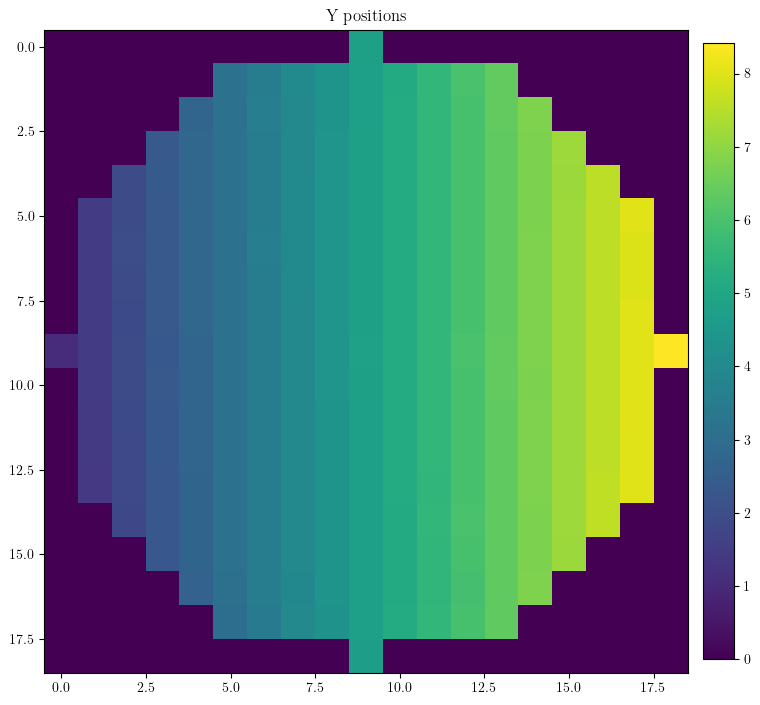

In [35]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_R_Y) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("Y positions")

<center> <b>Analysis of the reference image</b> </center>

In [36]:
df_hpref = pd.read_csv('output_organized.txt', delim_whitespace = True, header=None)
# df_hpref = pd.read_csv('output-that-works.txt', delim_whitespace = True, header=None)

C:\Users\PC\AppData\Local\Temp\ipykernel_20620\2008208621.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_hpref = pd.read_csv('output_organized.txt', delim_whitespace = True, header=None)


In [37]:
df_hpref.shape[0]

253

In [38]:
df_hpref.rename(columns={0:'pos', 2:'y', 1:'x'}, inplace=True)

In [39]:
df_hpref.head(3)

,pos,x,y
0,1,57,243
1,2,75,162
2,4,76,203


In [40]:
matA_hpref = np.zeros((480,480))

In [41]:
#This code corresponds to the scale stablished from pixels to distance. It is 0.02mm per pixel
delta = 0.02
X = np.linspace(0, 480*delta + delta, 480)

In [42]:
df_img_ref = np.floor(df_hpref).astype(int)

In [43]:
df_img_ref.head(5)

,pos,x,y
0,1,57,243
1,2,75,162
2,4,76,203
3,5,76,223
4,6,76,244


In [44]:
N = df_hpref.shape[0] #Number of centroids in the pattern

counter = 0 #Just to verify
for ii in range(0,N):
    matA_hpref[df_img_ref["y"][ii]][df_img_ref["x"][ii]] = 1
    counter += 1
counter 

253

Text(0, 0.5, 'Height [pixels]')

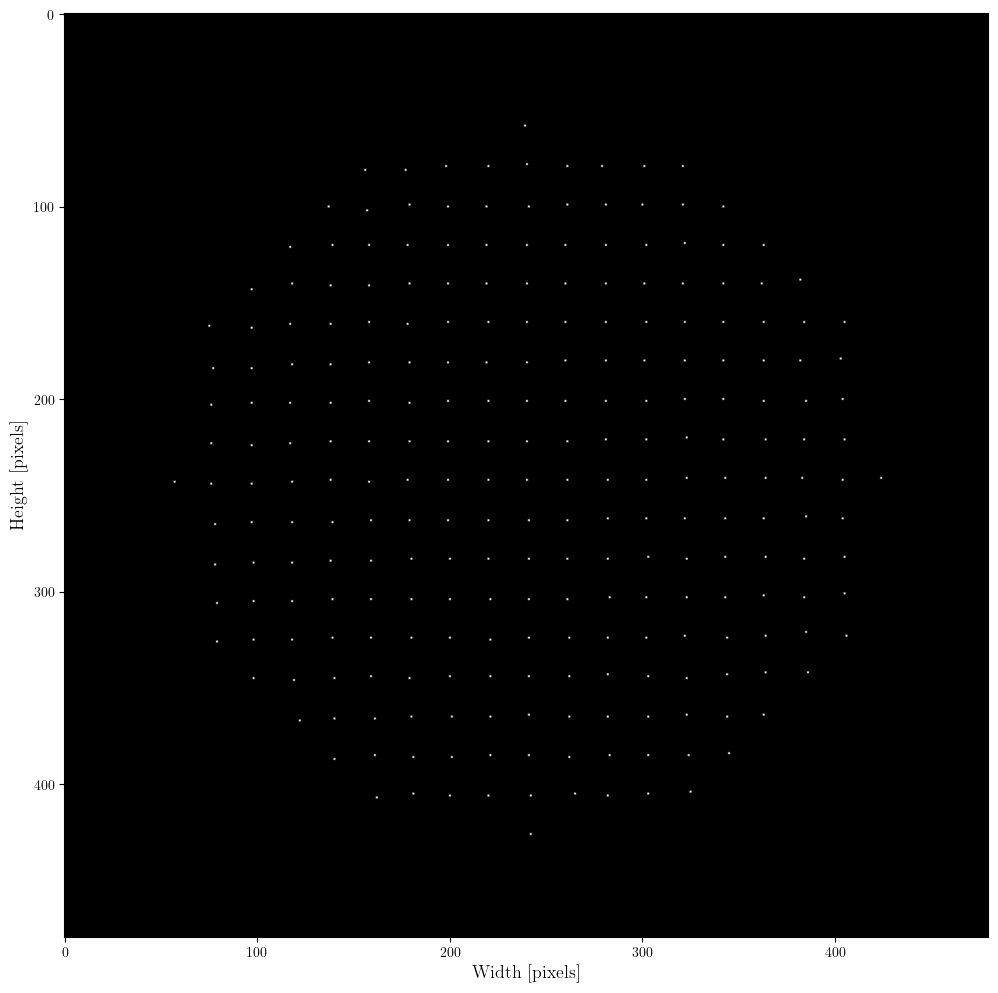

In [45]:
plt.figure(figsize=(12,12))
plt.imshow(matA_hpref, cmap="grey")
plt.xlabel('Width [pixels]', size=13)
plt.ylabel('Height [pixels]', size=13)

<center><b> Comparison between the pattern of points generated by reference surface and right eye <center><b>

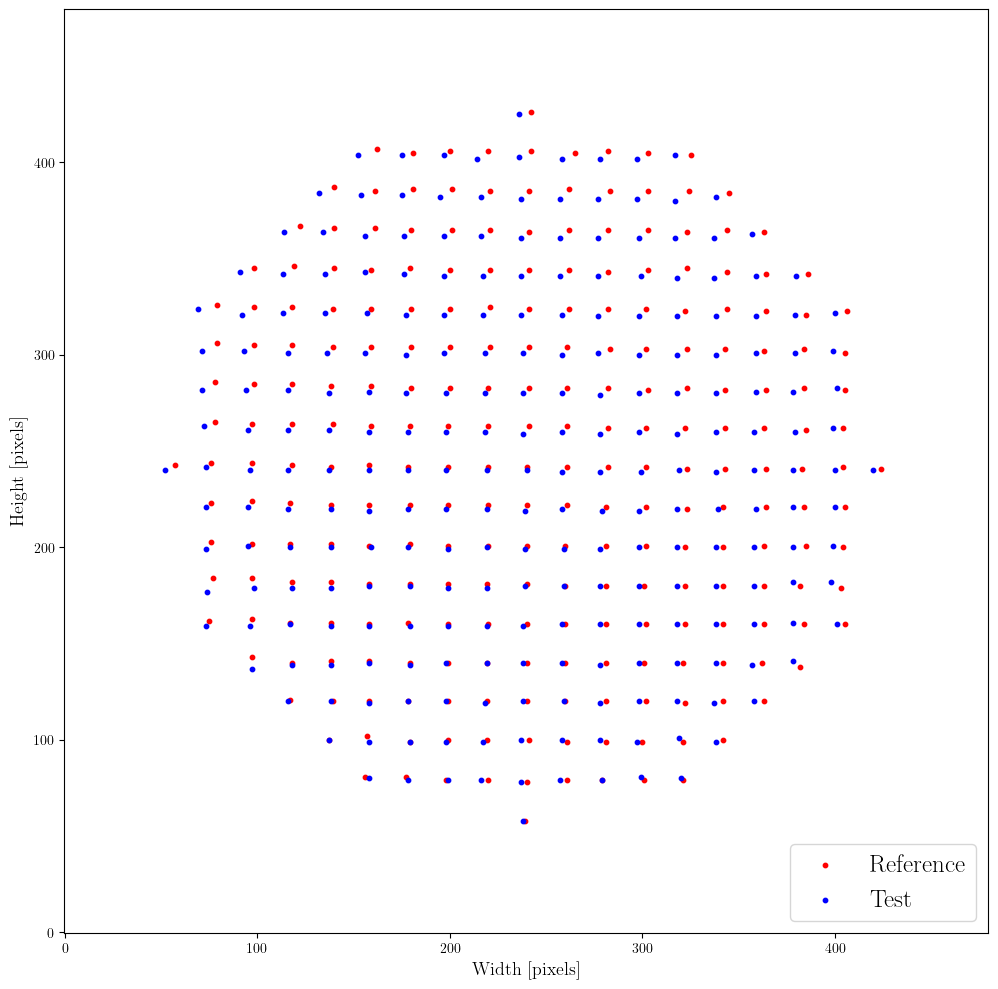

In [46]:
plt.figure(figsize=(12,12))

x1, y1 = np.nonzero(matA_hpref)  # rows, cols
y2, x2 = np.nonzero(matA)

plt.imshow(np.ones_like(matA), cmap="gray", vmin=0, vmax=1)

# Plot nonzero points as scatter
plt.scatter(y1, x1, c="red", s=10, label="Reference")   # s = markersize
plt.scatter(x2, y2, c="blue", s=10, label="Test")

plt.xlabel('Width [pixels]', size=13)
plt.ylabel('Height [pixels]', size=13)
plt.legend(fontsize=18, loc="lower right")
plt.gca().invert_yaxis()  # optional, to match image coordinates
plt.show()


In [47]:
df_hpref["x_d"] = df_hpref["x"] * delta
df_hpref["y_d"] = df_hpref["y"] * delta

In [48]:
df_hpref.head(10)

,pos,x,y,x_d,y_d
0,1,57,243,1.14,4.86
1,2,75,162,1.50,3.24
2,4,76,203,1.52,4.06
3,5,76,223,1.52,4.46
4,6,76,244,1.52,4.88
5,3,77,184,1.54,3.68
6,7,78,265,1.56,5.30
7,8,78,286,1.56,5.72
8,9,79,306,1.58,6.12
9,10,79,326,1.58,6.52


In [49]:
mat_R_X_hpref = np.zeros((19,19))

In [50]:
mat_R_X_hpref[0][9] = df_hpref["x_d"][0]

mat_R_X_hpref[1][5] = df_hpref["x_d"][1]
mat_R_X_hpref[1][6] = df_hpref["x_d"][2]
mat_R_X_hpref[1][7] = df_hpref["x_d"][3]
mat_R_X_hpref[1][8] = df_hpref["x_d"][4]
mat_R_X_hpref[1][9] = df_hpref["x_d"][5]
mat_R_X_hpref[1][10] = df_hpref["x_d"][6]
mat_R_X_hpref[1][11] = df_hpref["x_d"][7]
mat_R_X_hpref[1][12] = df_hpref["x_d"][8]
mat_R_X_hpref[1][13] = df_hpref["x_d"][9]

mat_R_X_hpref[2][4] = df_hpref["x_d"][10]
mat_R_X_hpref[2][5] = df_hpref["x_d"][11]
mat_R_X_hpref[2][6] = df_hpref["x_d"][12]
mat_R_X_hpref[2][7] = df_hpref["x_d"][13]
mat_R_X_hpref[2][8] = df_hpref["x_d"][14]
mat_R_X_hpref[2][9] = df_hpref["x_d"][15]
mat_R_X_hpref[2][10] = df_hpref["x_d"][16]
mat_R_X_hpref[2][11] = df_hpref["x_d"][17]
mat_R_X_hpref[2][12] = df_hpref["x_d"][18]
mat_R_X_hpref[2][13] = df_hpref["x_d"][19]
mat_R_X_hpref[2][14] = df_hpref["x_d"][20]

mat_R_X_hpref[3][3] = df_hpref["x_d"][21]
mat_R_X_hpref[3][4] = df_hpref["x_d"][22]
mat_R_X_hpref[3][5] = df_hpref["x_d"][23]
mat_R_X_hpref[3][6] = df_hpref["x_d"][24]
mat_R_X_hpref[3][7] = df_hpref["x_d"][25]
mat_R_X_hpref[3][8] = df_hpref["x_d"][26]
mat_R_X_hpref[3][9] = df_hpref["x_d"][27]
mat_R_X_hpref[3][10] = df_hpref["x_d"][28]
mat_R_X_hpref[3][11] = df_hpref["x_d"][29]
mat_R_X_hpref[3][12] = df_hpref["x_d"][30]
mat_R_X_hpref[3][13] = df_hpref["x_d"][31]
mat_R_X_hpref[3][14] = df_hpref["x_d"][32]
mat_R_X_hpref[3][15] = df_hpref["x_d"][33]

mat_R_X_hpref[4][2] = df_hpref["x_d"][34]
mat_R_X_hpref[4][3] = df_hpref["x_d"][35]
mat_R_X_hpref[4][4] = df_hpref["x_d"][36]
mat_R_X_hpref[4][5] = df_hpref["x_d"][37]
mat_R_X_hpref[4][6] = df_hpref["x_d"][38]
mat_R_X_hpref[4][7] = df_hpref["x_d"][39]
mat_R_X_hpref[4][8] = df_hpref["x_d"][40]
mat_R_X_hpref[4][9] = df_hpref["x_d"][41]
mat_R_X_hpref[4][10] = df_hpref["x_d"][42]
mat_R_X_hpref[4][11] = df_hpref["x_d"][43]
mat_R_X_hpref[4][12] = df_hpref["x_d"][44]
mat_R_X_hpref[4][13] = df_hpref["x_d"][45]
mat_R_X_hpref[4][14] = df_hpref["x_d"][46]
mat_R_X_hpref[4][15] = df_hpref["x_d"][47]
mat_R_X_hpref[4][16] = df_hpref["x_d"][48]

In [51]:
counter = 49
for ii in range(5,14):
    if (ii == 9 ):
        for jj in range(0, 19):
            mat_R_X_hpref[ii][jj] = df_hpref["x_d"][counter]     
            counter+=1        
    else:
        for jj in range(1,18):
            mat_R_X_hpref[ii][jj] = df_hpref["x_d"][counter] 
            counter+=1

In [52]:
mat_R_X_hpref[14][2] = df_hpref["x_d"][204]
mat_R_X_hpref[14][3] = df_hpref["x_d"][205]
mat_R_X_hpref[14][4] = df_hpref["x_d"][206]
mat_R_X_hpref[14][5] = df_hpref["x_d"][207]
mat_R_X_hpref[14][6] = df_hpref["x_d"][208]
mat_R_X_hpref[14][7] = df_hpref["x_d"][209]
mat_R_X_hpref[14][8] = df_hpref["x_d"][210]
mat_R_X_hpref[14][9] = df_hpref["x_d"][211]
mat_R_X_hpref[14][10] = df_hpref["x_d"][212]
mat_R_X_hpref[14][11] = df_hpref["x_d"][213]
mat_R_X_hpref[14][12] = df_hpref["x_d"][214]
mat_R_X_hpref[14][13] = df_hpref["x_d"][215]
mat_R_X_hpref[14][14] = df_hpref["x_d"][216]
mat_R_X_hpref[14][15] = df_hpref["x_d"][217]
mat_R_X_hpref[14][16] = df_hpref["x_d"][218]

mat_R_X_hpref[15][3] = df_hpref["x_d"][219]
mat_R_X_hpref[15][4] = df_hpref["x_d"][220]
mat_R_X_hpref[15][5] = df_hpref["x_d"][221]
mat_R_X_hpref[15][6] = df_hpref["x_d"][222]
mat_R_X_hpref[15][7] = df_hpref["x_d"][223]
mat_R_X_hpref[15][8] = df_hpref["x_d"][224]
mat_R_X_hpref[15][9] = df_hpref["x_d"][225]
mat_R_X_hpref[15][10] = df_hpref["x_d"][226]
mat_R_X_hpref[15][11] = df_hpref["x_d"][227]
mat_R_X_hpref[15][12] = df_hpref["x_d"][228]
mat_R_X_hpref[15][13] = df_hpref["x_d"][229]
mat_R_X_hpref[15][14] = df_hpref["x_d"][230]
mat_R_X_hpref[15][15] = df_hpref["x_d"][231]

mat_R_X_hpref[16][4] = df_hpref["x_d"][232]
mat_R_X_hpref[16][5] = df_hpref["x_d"][233]
mat_R_X_hpref[16][6] = df_hpref["x_d"][234]
mat_R_X_hpref[16][7] = df_hpref["x_d"][235]
mat_R_X_hpref[16][8] = df_hpref["x_d"][236]
mat_R_X_hpref[16][9] = df_hpref["x_d"][237]
mat_R_X_hpref[16][10] = df_hpref["x_d"][238]
mat_R_X_hpref[16][11] = df_hpref["x_d"][239]
mat_R_X_hpref[16][12] = df_hpref["x_d"][240]
mat_R_X_hpref[16][13] = df_hpref["x_d"][241]
mat_R_X_hpref[16][14] = df_hpref["x_d"][242]

mat_R_X_hpref[17][5] = df_hpref["x_d"][243]
mat_R_X_hpref[17][6] = df_hpref["x_d"][244]
mat_R_X_hpref[17][7] = df_hpref["x_d"][245]
mat_R_X_hpref[17][8] = df_hpref["x_d"][246]
mat_R_X_hpref[17][9] = df_hpref["x_d"][247]
mat_R_X_hpref[17][10] = df_hpref["x_d"][248]
mat_R_X_hpref[17][11] = df_hpref["x_d"][249]
mat_R_X_hpref[17][12] = df_hpref["x_d"][250]
mat_R_X_hpref[17][13] = df_hpref["x_d"][251]

mat_R_X_hpref[18][9] = df_hpref["x_d"][252]

Text(0.5, 1.0, 'Y positions')

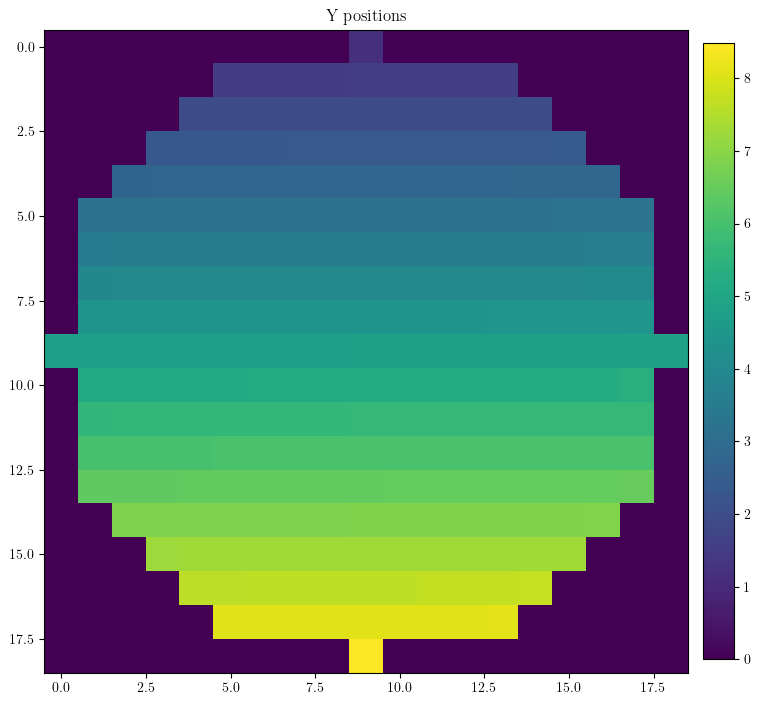

In [53]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_R_X_hpref) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("Y positions")

<b>                 ---------------------------------------------------------------------------------------------------------------- </b>

Now, we are going to iterate across the whole matrix and implement the algorithm to find the **astigmatism** in each point (those one that are meaningfull for us and the algorithm works)

In [65]:
mat_C = np.zeros((19,19))

In [66]:
ro = 0.4
R = 7.78
for ii in range(1,18): #This limits were stablished in order to avoid violating the range in which the matrix is defined
    for jj in range(1,18):
        x_looking = mat_R_X[ii-1][jj] != 0 and mat_R_X[ii+1][jj]!=0 and mat_R_X[ii][jj+1]!=0 and mat_R_X[ii][jj-1]!=0
        y_looking = mat_R_Y[ii-1][jj] != 0 and mat_R_Y[ii+1][jj]!=0 and mat_R_Y[ii][jj+1]!=0 and mat_R_Y[ii][jj-1]!=0
        if ((mat_R_X[ii][jj]!=0 and mat_R_Y[ii][jj]!= 0) and x_looking and y_looking):
            center_x_coord = mat_R_X[ii][jj]
            delta_x_a = mat_R_X[ii+1][jj] - center_x_coord
            delta_x_c = mat_R_X[ii-1][jj] - center_x_coord
            delta_x_b = mat_R_X[ii][jj+1] - center_x_coord
            delta_x_d = mat_R_X[ii][jj-1] - center_x_coord

            center_y_coord = mat_R_Y[ii][jj]
            delta_y_a = mat_R_Y[ii+1][jj] - center_y_coord
            delta_y_b = mat_R_Y[ii][jj+1] - center_y_coord
            delta_y_d = mat_R_Y[ii][jj-1] - center_y_coord

            first_factor = ((delta_x_a-delta_x_c) -(delta_y_b - delta_y_d))/(2*ro*R)
            second_factor = ((delta_x_b-delta_x_d)-(delta_y_a - delta_y_b))/(2*ro*R)

            C = (first_factor**2 + second_factor**2)**(1/2)

            mat_C[ii][jj] = C

C:\Users\PC\AppData\Local\Temp\ipykernel_20620\128981134.py:2: RuntimeWarning: divide by zero encountered in divide
  im = plt.imshow(1000/mat_C)


Text(0.5, 1.0, 'Astigmatism')

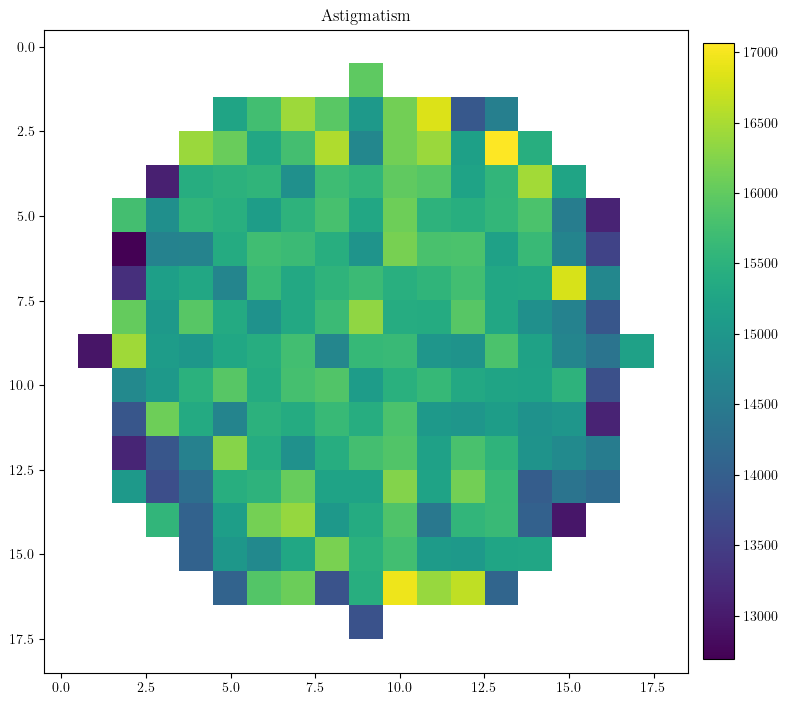

In [67]:
plt.figure(figsize=(10, 10))
im = plt.imshow(1000/mat_C) 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("Astigmatism")

In [62]:

ro = 0.4
R = 7.78

# assume mat_R_X, mat_R_Y, mat_C are numpy arrays with same shape
N, M = mat_R_X.shape

# safe loops (skip borders)
for ii in range(1, N-1):
    for jj in range(1, M-1):
        # neighbor checks (already fixed by you — keep for X and Y separately)
        x_ok = (
            mat_R_X[ii-1, jj] != 0 and
            mat_R_X[ii+1, jj] != 0 and
            mat_R_X[ii, jj+1] != 0 and
            mat_R_X[ii, jj-1] != 0
        )
        y_ok = (
            mat_R_Y[ii-1, jj] != 0 and
            mat_R_Y[ii+1, jj] != 0 and
            mat_R_Y[ii, jj+1] != 0 and
            mat_R_Y[ii, jj-1] != 0
        )

        # current behavior: require both centers non-zero
        if (mat_R_X[ii, jj] != 0 and mat_R_Y[ii, jj] != 0) and x_ok and y_ok:
            cx = mat_R_X[ii, jj]
            cy = mat_R_Y[ii, jj]

            # symmetrical deltas (up/down/left/right)
            dx_up    = mat_R_X[ii-1, jj] - cx
            dx_down  = mat_R_X[ii+1, jj] - cx
            dx_left  = mat_R_X[ii, jj-1] - cx
            dx_right = mat_R_X[ii, jj+1] - cx

            dy_up    = mat_R_Y[ii-1, jj] - cy
            dy_down  = mat_R_Y[ii+1, jj] - cy
            dy_left  = mat_R_Y[ii, jj-1] - cy
            dy_right = mat_R_Y[ii, jj+1] - cy

            # symmetric finite-difference-like expressions
            first_factor  = ((dx_down - dx_up) - (dy_right - dy_left)) / (2 * ro * R)
            second_factor = ((dx_right - dx_left) - (dy_down - dy_up)) / (2 * ro * R)

            C = np.hypot(first_factor, second_factor)  # sqrt(a^2 + b^2)
            mat_C[ii, jj] = C


In [63]:

eps = 1e-8  # threshold for "non-zero"

def is_valid(v):
    return np.isfinite(v) and abs(v) > eps

ro = 0.4
R = 7.78
N, M = mat_R_X.shape

for ii in range(1, N-1):
    for jj in range(1, M-1):
        cx = mat_R_X[ii, jj]
        cy = mat_R_Y[ii, jj]

        center_ok = is_valid(cx) and is_valid(cy)

        x_ok = (is_valid(mat_R_X[ii-1, jj]) and is_valid(mat_R_X[ii+1, jj])
                and is_valid(mat_R_X[ii, jj+1]) and is_valid(mat_R_X[ii, jj-1]))

        y_ok = (is_valid(mat_R_Y[ii-1, jj]) and is_valid(mat_R_Y[ii+1, jj])
                and is_valid(mat_R_Y[ii, jj+1]) and is_valid(mat_R_Y[ii, jj-1]))

        if center_ok and x_ok and y_ok:
            dx_up    = mat_R_X[ii-1, jj] - cx
            dx_down  = mat_R_X[ii+1, jj] - cx
            dx_left  = mat_R_X[ii, jj-1] - cx
            dx_right = mat_R_X[ii, jj+1] - cx

            dy_up    = mat_R_Y[ii-1, jj] - cy
            dy_down  = mat_R_Y[ii+1, jj] - cy
            dy_left  = mat_R_Y[ii, jj-1] - cy
            dy_right = mat_R_Y[ii, jj+1] - cy

            first_factor  = ((dx_down - dx_up) - (dy_right - dy_left)) / (2 * ro * R)
            second_factor = ((dx_right - dx_left) - (dy_down - dy_up)) / (2 * ro * R)
            mat_C[ii, jj] = (first_factor**2 + second_factor**2)**0.5


(-0.5, 18.5, 18.5, -0.5)

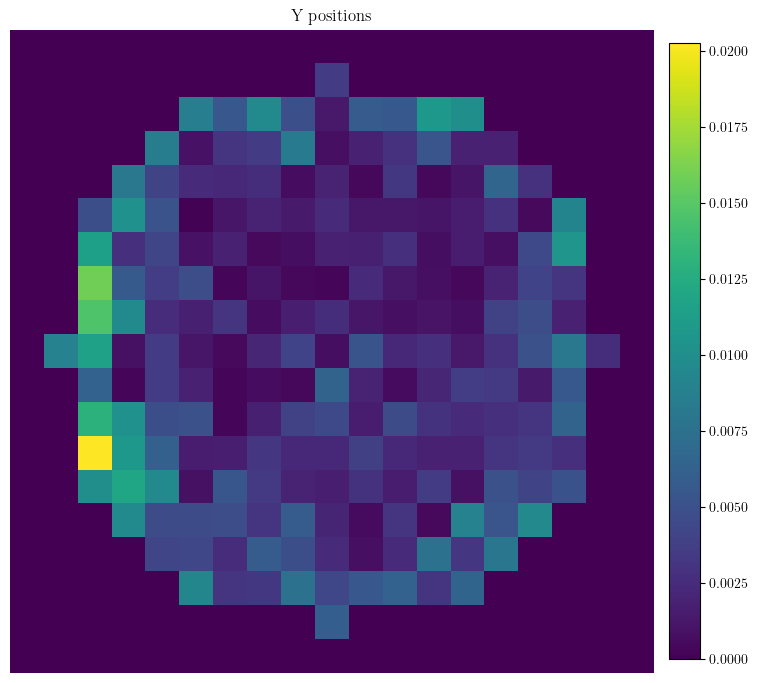

In [64]:
plt.figure(figsize=(10, 10))
im = plt.imshow(mat_C, cmap="viridis") 
cbar = plt.colorbar(im, shrink=0.8, pad=0.02) 
plt.title("Y positions")
plt.axis('off')